In [1]:
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from pathlib import Path
from torchinfo import summary
from PIL import Image

C:\Users\seifm\PycharmProjects\PythonProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train_dir = "../data/food/train"
test_dir = "../data/food/test"

In [3]:
#make the device agnostic
device= "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [4]:
#make transformer
manual_transformer = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])
train_dataloader , test_dataloader ,classes = data_setter_loader.data_setter_loader(train_dir, test_dir, manual_transformer, 32, 1)

In [5]:
#making the table one hyper parameters
NUM_LAYERS = 12
HIDDEN_SIZE_D= 768
MLP_SIZE = 3072
NUM_HEADS = 12

# EQUATION 1
$$z_0 = [x_{class}; x_p^1 E; x_p^2 E; \dots; x_p^N E] + E_{pos}$$
x_input = [class_token, image_patch_1, image_patch_2, ... image_patch_N] + position embeding

In [6]:
height = 224
width = 224
color_channels = 3
patch_size = 16
print(f"input --->  ({color_channels},{height},{width})")
print(f"output -->  ({(height*width)//(patch_size*patch_size)},{patch_size*2*color_channels})")

input --->  (3,224,224)
output -->  (196,96)


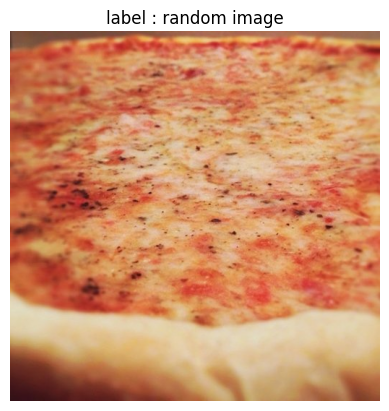

In [43]:
#visualizing a random image
list_images_train = list(Path(train_dir).glob("*/*.jpg"))
random_image_path_beggining = random.sample(list_images_train,1)
random_image_beggining = Image.open(random_image_path_beggining[0])
plt.figure()
plt.imshow(random_image_beggining)
plt.title("label : random image")
plt.axis(False)
plt.show()

In [8]:
#getting random image from the dataloader
dataloader_iter = iter(train_dataloader)
images_dataloader,labels_dataloader  = next(dataloader_iter)
random_index_for_dataloader = random.randint(0,len(images_dataloader)-1)

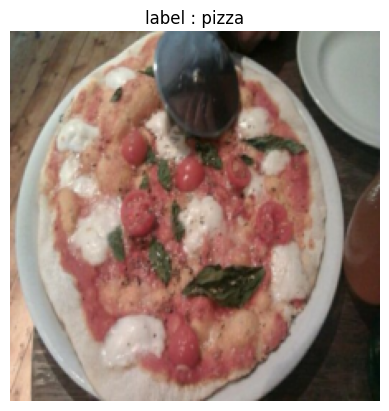

In [9]:
random_image_dataloader = images_dataloader[random_index_for_dataloader]
permuted_image_dataloader = random_image_dataloader.permute(1,2,0)
plt.figure()
plt.imshow(permuted_image_dataloader)
plt.title(f"label : {classes[labels_dataloader[random_index_for_dataloader]]}")
plt.axis(False)
plt.show()


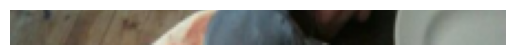

In [10]:
plt.figure()
plt.imshow(permuted_image_dataloader[:patch_size,:,:])
plt.axis(False)
plt.show()

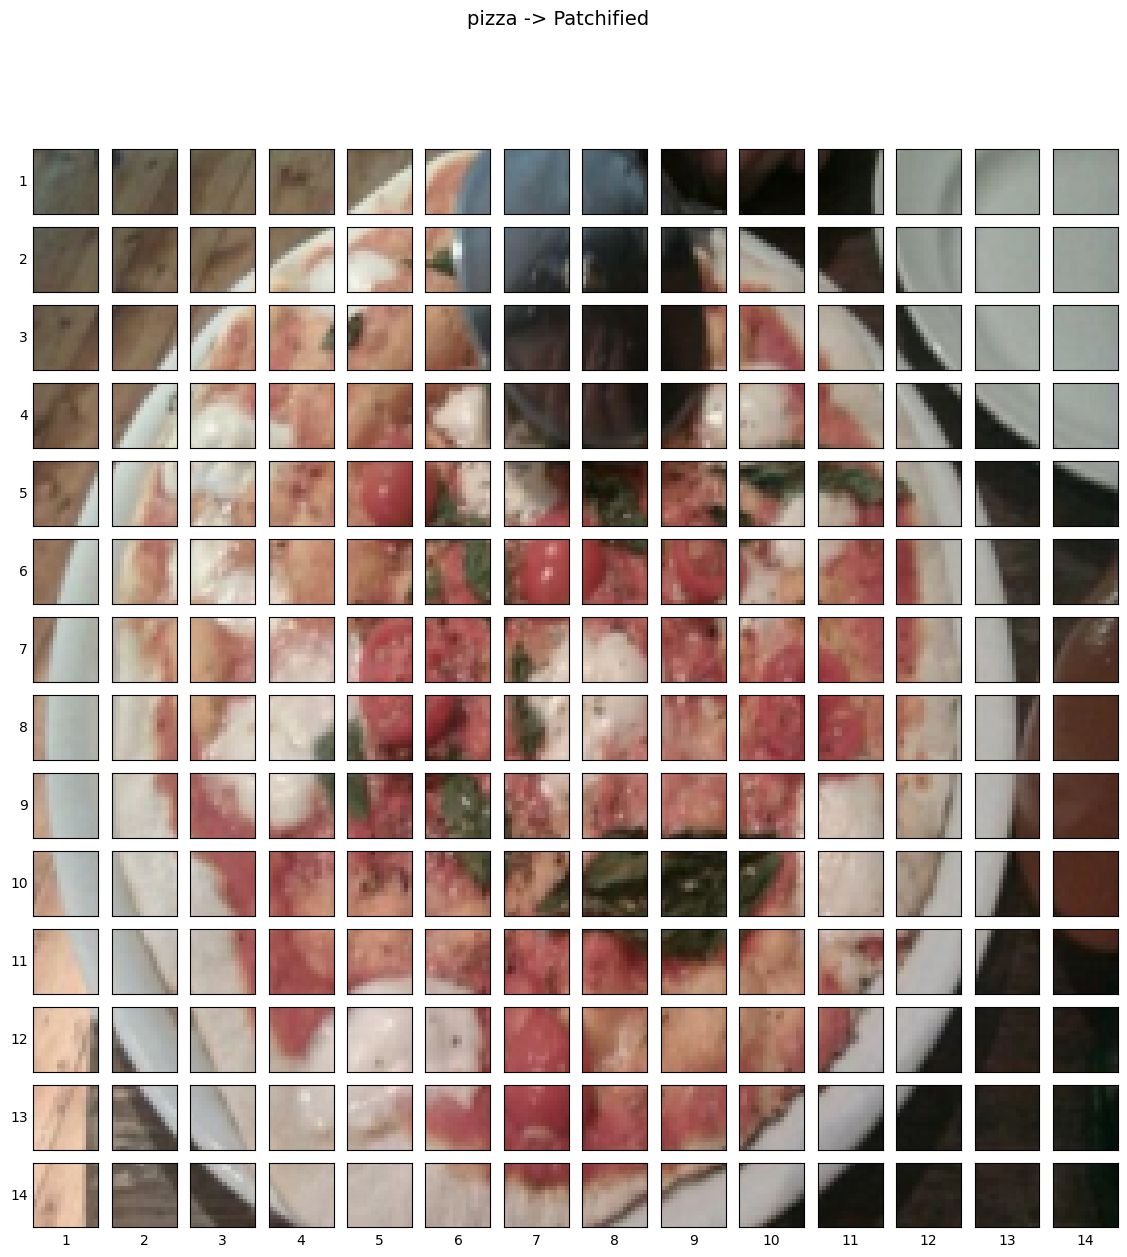

In [11]:
#make a code to plot the whole image --> pataches
image_size = 224
patch_size = 16
number_patches = image_size//patch_size #this  is per side if we make 14*14 we get --> 196 patches
assert image_size%patch_size == 0 , "there is no compatibality between the size of the image and patch"
fig , axs = plt.subplots(nrows=number_patches,
                         ncols=number_patches,
                         figsize=(number_patches,number_patches),
                         sharex=True,
                         sharey=True)
for i , patch_height in enumerate(range(0,image_size,16)):
    for j,patch_width in enumerate(range(0,image_size,16)):
        axs[i,j].imshow(permuted_image_dataloader[patch_height:patch_height+patch_size, # iterate through height
                                    patch_width:patch_width+patch_size, # iterate through width
                                    :]) # get all color channel

        #permuted_image_dataloader[0:16, 0:16, :]
                                   # ↑     ↑    ↑
                                   # |     |    all colors
                                   # |     pixels 0-15 (width)
                                   # pixels 0-15 (height)

        axs[i, j].set_ylabel(i+1,
                         rotation="horizontal",
                         horizontalalignment="right",
                             verticalalignment="center")
        axs[i, j].set_xlabel(j+1)
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        axs[i, j].label_outer()

# Set up a title for the plot
fig.suptitle(f"{classes[labels_dataloader[random_index_for_dataloader]]} -> Patchified", fontsize=14)
plt.show()

In [12]:
 image_size//patch_size

14

In [13]:
#making patch embeding by using the conv2d
conv2d = nn.Conv2d(in_channels=color_channels,
                   out_channels=HIDDEN_SIZE_D,
                   kernel_size=patch_size,
                   stride=patch_size,
                   padding = 0)
conv2d

Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))

In [14]:
random_image_dataloader.shape

torch.Size([3, 224, 224])

In [15]:
conv2d_output_image = conv2d(random_image_dataloader.unsqueeze(dim=0))
conv2d_output_image.shape
conv2d_output_image.shape

torch.Size([1, 768, 14, 14])

In [16]:
(224*224*3)//196
# 196 is (14*14) and this is that there is 14*14 patches dimensions in every part of the RGB in the image 14*14 in red and 14*14 in the blue and 14*14 in the green

768

for here to clarify what is happening:
 OR  in other words every patch is 16 * 16 pixel ---> 256 pixel ,and this is for the full connected photo and if we make the photo to R,G,B the values that is  in every patch is 256 * 3---->768 values, and this is the thing the the conv2d makes is that:
   * it makes the image to patches --> 196 in our case
   * it makes every patch(196) into values (number) (768 in our case)

random indicies[71, 578, 27, 417, 375]


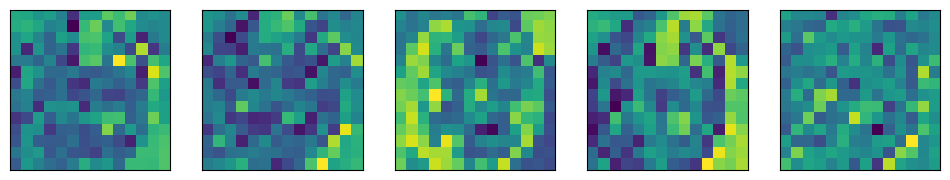

In [17]:
#visualize some of the features --> there we are going to see one feature from the 768 features or values in each of the  14*14--> 196 patch in one photo
randon_indexes = random.sample(range(768),5)
print(f"random indicies{randon_indexes}")
fig,axs = plt.subplots(nrows=1,ncols=5,figsize=(12,12))

for i,index in enumerate(randon_indexes):
    feature_in_all_patches = conv2d_output_image[:,index,:,:]
    axs[i].imshow(feature_in_all_patches.squeeze().detach().numpy())  # remove batch dimension, and remove from grad tracking/switch to numpy for matplotlib
    axs[i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])


In [18]:
single_feature = conv2d_output_image[:,5,:,:]
single_feature

tensor([[[-0.5619, -0.5277, -0.6057, -0.5774, -0.9826, -0.8575, -0.6607,
          -0.5077, -0.1512, -0.1160, -0.1530, -0.9106, -0.9710, -0.9759],
         [-0.5361, -0.5204, -0.7748, -1.1630, -1.1495, -0.9201, -0.3857,
          -0.1976, -0.3848, -0.9664, -0.3376, -0.9216, -1.0345, -0.9706],
         [-0.5449, -0.7377, -1.0891, -1.0116, -0.7985, -0.6687, -0.2986,
          -0.1846, -0.3340, -0.6570, -1.0550, -0.7828, -1.0471, -0.9927],
         [-0.6065, -1.0859, -1.2498, -0.8959, -0.7537, -1.2422, -0.3327,
          -0.2667, -0.5790, -0.9809, -0.8364, -0.7641, -0.7665, -0.9978],
         [-0.7269, -1.1029, -1.1603, -0.8950, -0.6760, -0.7184, -0.7739,
          -0.3188, -0.5211, -0.5159, -0.5372, -0.9941, -0.2194, -0.2449],
         [-1.0226, -0.9618, -1.2858, -0.9659, -0.7636, -0.5919, -0.6573,
          -0.6035, -0.5889, -0.9178, -0.7545, -1.0395, -0.3877, -0.3360],
         [-1.1813, -0.9888, -0.8932, -1.1447, -0.7422, -0.7308, -0.9019,
          -1.2074, -0.7196, -0.7767, -0.8370,

In [19]:
#flattening the (..,14,14) layer to make it (...,196) and put it in the beggining to be --->
#(1,196,768) (batch_size,number_of_patches, embedding_dimension)

flatten_layer = nn.Flatten(start_dim=2, end_dim=3)
flatten_conv2d_img = flatten_layer(conv2d_output_image)
flatten_conv2d_img_permuted = flatten_conv2d_img.permute(0,2,1)
print(f"After flattening: {flatten_conv2d_img.shape} , then permute: {flatten_conv2d_img_permuted.shape}")

After flattening: torch.Size([1, 768, 196]) , then permute: torch.Size([1, 196, 768])


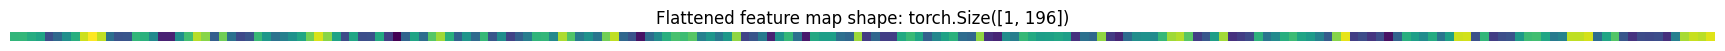

In [20]:
##visulualize single feature now
single_feature_of_flatten_conv2d_img_permuted = flatten_conv2d_img_permuted[:,:,2]
# Plot the flattened feature map visually
plt.figure(figsize=(22, 22))
plt.imshow(single_feature_of_flatten_conv2d_img_permuted.detach().numpy())
plt.title(f"Flattened feature map shape: {single_feature_of_flatten_conv2d_img_permuted.shape}")
plt.axis(False);

### making the whole thing into some class that inherite the (nn.Module)

In [21]:
class Patch_embeding(nn.Module):
    def __init__(self,
                 patch_size=16,
                 in_channels=3,
                 embed_dim=768):
        super().__init__()

        self.patch_size = patch_size
        self.patcher =nn.Conv2d(in_channels=in_channels,
                                out_channels=embed_dim,
                                kernel_size=patch_size,
                                stride=patch_size,
                                padding=0)
        self.flatten = nn.Flatten(start_dim=2,end_dim=3)

    #make the foreward
    def forward(self, x):
        #check for error
        image_dim = x.shape[-1]
        assert image_dim % self.patch_size==0 , f"Input image size must be divisible by patch size, image shape: {image_dim}, patch size: {self.patch_size}"
        #make it
        return self.flatten(self.patcher(x)).permute(0,2,1)


In [22]:
#lets try it
patchify = Patch_embeding()
patchify_image_functions_try=patchify(random_image_dataloader.unsqueeze(dim=0))# bec conv2d should have batch dimension
print(f"shape: {random_image_dataloader.shape} ---> {patchify_image_functions_try.shape} ")

shape: torch.Size([3, 224, 224]) ---> torch.Size([1, 196, 768]) 


### making the class token:
Summary:
The class token is created to:

* information from all 196 patches
* Learn a summary of the entire image
* Predict the class based on that summary

Without it: You'd have 196 outputs (one per patch), not 1 output for classification! 👍

In [23]:
batch_size = patchify_image_functions_try.shape[0]
embeding_dimension = HIDDEN_SIZE_D # or  patchify_image_functions_try.shape[-1]
batch_size  , embeding_dimension

(1, 768)

In [24]:
#make the token
class_token = nn.Parameter(torch.ones(batch_size,1,embeding_dimension), # it should be (rand) not (ones)
                           requires_grad=True)
class_token.shape

torch.Size([1, 1, 768])

In [25]:
#add it using cat
patched_img_class_token = torch.cat((class_token,patchify_image_functions_try),
                                    dim=1)#this is the patches dimension
print(patched_img_class_token)
patched_img_class_token.shape

tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
         [ 0.1489, -0.1764, -0.1293,  ..., -0.1680,  0.0409,  0.0368],
         [ 0.1336, -0.2074, -0.1184,  ..., -0.1686,  0.0749,  0.0148],
         ...,
         [ 0.0481, -0.0991, -0.0501,  ..., -0.0741,  0.0510,  0.0098],
         [ 0.0795, -0.0754, -0.0433,  ..., -0.0989,  0.0529,  0.0129],
         [ 0.0332, -0.0498, -0.0730,  ..., -0.0510,  0.0090,  0.0124]]],
       grad_fn=<CatBackward0>)


torch.Size([1, 197, 768])

### make the position embeding :
* it is what makes the model know what is this and what is the position of this and prevent the model from getting lost

In [26]:
number_patches = (224*224)//(16*16)
number_patches,embeding_dimension

(196, 768)

In [27]:
position_embeding = nn.Parameter(torch.ones(1,number_patches+1,embeding_dimension), requires_grad=True) # it should be (rand) not (ones)
position_embeding.shape

torch.Size([1, 197, 768])

In [28]:
final_class_and_position_embeding = patched_img_class_token+position_embeding
print(final_class_and_position_embeding)
final_class_and_position_embeding.shape

tensor([[[2.0000, 2.0000, 2.0000,  ..., 2.0000, 2.0000, 2.0000],
         [1.1489, 0.8236, 0.8707,  ..., 0.8320, 1.0409, 1.0368],
         [1.1336, 0.7926, 0.8816,  ..., 0.8314, 1.0749, 1.0148],
         ...,
         [1.0481, 0.9009, 0.9499,  ..., 0.9259, 1.0510, 1.0098],
         [1.0795, 0.9246, 0.9567,  ..., 0.9011, 1.0529, 1.0129],
         [1.0332, 0.9502, 0.9270,  ..., 0.9490, 1.0090, 1.0124]]],
       grad_fn=<AddBackward0>)


torch.Size([1, 197, 768])

### remaking all of that again in one block

In [29]:
random_image_dataloader.shape

torch.Size([3, 224, 224])

In [30]:
random_image_dataloader_unsqueeezed = random_image_dataloader.unsqueeze(dim=0)
random_image_dataloader_unsqueeezed.shape

torch.Size([1, 3, 224, 224])

In [31]:
patchify = Patch_embeding()
con2d_flatten_image  = patchify(random_image_dataloader_unsqueeezed)
con2d_flatten_image.shape

torch.Size([1, 196, 768])

In [32]:
batch_size = con2d_flatten_image.shape[0]
embeding_dimension = con2d_flatten_image.shape[-1]
class_token = nn.Parameter(torch.rand(batch_size,1,embeding_dimension), requires_grad=True)
con2d_flatten_class_image = torch.cat((class_token,con2d_flatten_image),dim=1)
con2d_flatten_class_image.shape

torch.Size([1, 197, 768])

In [33]:
number_patches = (224*224)//(16*16)
position_embeding = nn.Parameter(torch.rand(1,number_patches+1,embeding_dimension), requires_grad=True)
con2d_flatten_class_position_image = con2d_flatten_class_image+position_embeding
con2d_flatten_class_position_image.shape

torch.Size([1, 197, 768])

# Equation 2:
$$z'_l = MSA(LN(z_{l-1})) + z_{l-1}, \quad l=1 \dots L$$
x_output_MSA_block = MSA_layer(LN_layer(x_input)) + x_input


In [34]:
class MultiHeadSelfAttention (nn.Module):
    def __init__(self,
                 embed_dim=HIDDEN_SIZE_D,
                 num_heads=NUM_HEADS,
                 attn_dropout=0):
        super().__init__()
        self.layer_Norm = nn.LayerNorm(normalized_shape=embed_dim)
        self.multi_atten =nn.MultiheadAttention(embed_dim, num_heads, dropout=attn_dropout, batch_first=True)

    def forward (self,x) :
        x = self.layer_Norm(x)
        attn_output, _ = self.multi_atten(query=x,key=x,value=x,need_weights=False) # the (_) is the attention weight which we are not usoiing now
        return attn_output


In [35]:
multi_self_attention_block = MultiHeadSelfAttention()
eq_1_img_MSA = multi_self_attention_block(con2d_flatten_class_position_image)
print((con2d_flatten_class_position_image.shape))
eq_1_img_MSA.shape

torch.Size([1, 197, 768])


torch.Size([1, 197, 768])

# EQUATION 3:
$$z_l = MLP(LN(z'_l)) + z'_l, \quad l=1 \dots L$$
x_output_MLP_block = MLP_layer(LN_layer(x_output_MSA_block)) + x_output_MSA_block


In [36]:
class MLP_block (nn.Module):
    def __init__(self,
                 embed_dim=HIDDEN_SIZE_D,
                 mlp_size=MLP_SIZE,
                 dropout=0.1):
        super().__init__()
        self.layer_Norm = nn.LayerNorm(normalized_shape=embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, mlp_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_size, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self,x):
        return self.mlp(self.layer_Norm(x))

In [37]:
mlp_block = MLP_block()
eq_2_img_MLP = mlp_block(eq_1_img_MSA)
print(eq_2_img_MLP.shape)

torch.Size([1, 197, 768])


### EQUATION 4:
$$y = LN(z_L^0)$$
* it is just linear layer of our classification (classification head) , so we are going to put it with others without need for seperate section for it

# lets make TRNSFORMER ENCODER:
The Transformer Encoder is a combination of alternating blocks of MSA (equation 2) and MLP (equation 3).
* Encoder = turn a sequence into learnable representation
* Decoder = go from learn representation back to some sort of sequence

In pseudocode --> Transformer Encoder:
* x_input -> MSA_block -> [MSA_block_output + x_input] -> MLP_block -> [MLP_block_output + MSA_block_output + x_input] -> ...

In [38]:
# it is just combininng EQ.2 and EQ.3
class TransformerEncoderBlock(nn.Module):
    def __init__(self,
                 embed_dim=HIDDEN_SIZE_D,
                 num_heads=NUM_HEADS,
                 mlp_size=MLP_SIZE,
                 dropout=0.1,
                 attn_dropout=0):
        super().__init__()
        self.msa_block = MultiHeadSelfAttention(HIDDEN_SIZE_D,NUM_HEADS,attn_dropout)
        self.mlp_block = MLP_block(embed_dim, mlp_size, dropout)

    def forward(self,x):
        x = self.msa_block(x) + x
        x = self.mlp_block(x) + x
        return x

In [39]:
transform_encoder_block = TransformerEncoderBlock()
summary(transform_encoder_block,
        input_size=(1, 197, 768), #(batch_size, number_of_patches, embedding_dimension))
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderBlock (TransformerEncoderBlock)  [1, 197, 768]        [1, 197, 768]        --                   True
├─MultiHeadSelfAttention (msa_block)               [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_Norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─MultiheadAttention (multi_atten)            --                   [1, 197, 768]        2,362,368            True
├─MLP_block (mlp_block)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_Norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─Sequential (mlp)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─Linear (0)                     

## we can the transformer encoder from the pytorch library

In [40]:
torch_transformer_encoder_layer = nn.TransformerEncoderLayer(d_model=HIDDEN_SIZE_D,
                                                             nhead=NUM_HEADS,
                                                             dim_feedforward=MLP_SIZE,
                                                             dropout=0.1,
                                                             activation="gelu",
                                                             batch_first=True,
                                                             norm_first=True)
torch_transformer_encoder_layer

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
  )
  (linear1): Linear(in_features=768, out_features=3072, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=3072, out_features=768, bias=True)
  (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

In [41]:
summary(torch_transformer_encoder_layer,
        input_size=(1, 197, 768), #(batch_size, number_of_patches, embedding_dimension))
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderLayer (TransformerEncoderLayer)  [1, 197, 768]        [1, 197, 768]        --                   True
├─LayerNorm (norm1)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─MultiheadAttention (self_attn)                   [1, 197, 768]        [1, 197, 768]        2,362,368            True
├─Dropout (dropout1)                               [1, 197, 768]        [1, 197, 768]        --                   --
├─LayerNorm (norm2)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─Linear (linear1)                                 [1, 197, 768]        [1, 197, 3072]       2,362,368            True
├─Dropout (dropout)                                [1, 197, 3072]       [1, 197, 3072]       --                   --
├─Linear (linear2)                             

# now putting all together and making **VIT MODEL**

In [46]:
class VITmodel (nn.Module):
    def __init__(self,
                 image_size=224,
                 in_channels=3,
                 patch_size=16,
                 num_transformer_layers=12,
                 embed_dim=HIDDEN_SIZE_D,
                 mlp_size=MLP_SIZE,
                 num_heads=NUM_HEADS,
                 mlp_dropout=0.1,
                 attn_dropout=0,
                 embedding_dropout=0.1,
                 num_classes=1000
                 ):
        super().__init__()
        assert image_size%patch_size==0 , f"Image size must be divisible by patch size, image: {image_size}, patch size: {patch_size}"
        self.num_patches = (image_size**2)//(patch_size**2)
        """
        self.num_patches  = Stores it as class attribute (accessible everywhere)
        num_patches = Just a local variable (only in __init__)

        Use self. when you need it in multiple methods! --> as we are going to use it in foreward  ✅
        """
        self.class_token = nn.Parameter(torch.rand(1,1,embed_dim), requires_grad=True)
        """
        CLASS TOKEN & BATCH SIZE:
            Why not hardcode batch_size in __init__?
            - Batch size varies: sometimes 1, sometimes 32, sometimes 64
            - Making it flexible allows any batch size without rebuilding the model ✅

        Solution:
            - Create with batch_size=1 in __init__
            - Expand/broadcast to actual batch_size in forward()
            - Works with any batch size automatically!
        MORE[INFO]:
            torch.cat() = requires exact dimensions → expand first
            addition (+) = broadcasts automatically → no need to expand
        """
        self.position_embed = nn.Parameter(torch.rand(1,self.num_patches+1,embed_dim), requires_grad=True)
        self.embedding_dropout = nn.Dropout(p=embedding_dropout)
        self.patch_embed = Patch_embeding(in_channels=in_channels,
                                          patch_size=patch_size,
                                          embed_dim=embed_dim)
        self.transformer_encoder_block = nn.Sequential(*[TransformerEncoderBlock(embed_dim=embed_dim,
                                                                                 num_heads=num_heads,
                                                                                 mlp_size=mlp_size,
                                                                                 dropout=mlp_dropout) for _ in range(num_transformer_layers)])
        """
        # Without (*)--> (unpacking operator):
        numbers = [1, 2, 3]
        print(numbers)  # [1, 2, 3]

        # With (*)-->(unpacking operator):
        print(*numbers)  # 1 2 3 (unpacked!)
        """
        # this is the classifier head
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes),
        )
    def forward(self,x):
        batch_size = x.shape[0]
        class_token = self.class_token.expand(batch_size,-1,-1)
        x = self.patch_embed(x)
        x = torch.cat((class_token,x), dim=1)
        x = self.position_embed + x
        x = self.embedding_dropout(x)
        x = self.transformer_encoder_block(x)
        x = self.classifier(x[:,0])
        """
        : means "all" by default
        [:, 0] gets all batches at position 0
         Class token is first because we put it first in torch.cat()
        """
        return x


In [47]:
#lets see if the model works
random_unreal_image = torch.randn(1,3,224,224)
vit_model = VITmodel(num_classes=3)
vit_model(random_unreal_image)

tensor([[-0.2441,  0.5066,  1.4497]], grad_fn=<AddmmBackward0>)

In [48]:
#see summery of the model
summary(vit_model,
        input_size=(1,3,224,224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                 Input Shape          Output Shape         Param #              Trainable
VITmodel (VITmodel)                                     [1, 3, 224, 224]     [1, 3]               152,064              True
├─Patch_embeding (patch_embed)                          [1, 3, 224, 224]     [1, 196, 768]        --                   True
│    └─Conv2d (patcher)                                 [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
│    └─Flatten (flatten)                                [1, 768, 14, 14]     [1, 768, 196]        --                   --
├─Dropout (embedding_dropout)                           [1, 197, 768]        [1, 197, 768]        --                   --
├─Sequential (transformer_encoder_block)                [1, 197, 768]        [1, 197, 768]        --                   True
│    └─TransformerEncoderBlock (0)                      [1, 197, 768]        [1, 197, 768]        --                   True
│    │ 

## lets now make optimizer and loss_fn and use the model

In [49]:
optimizer = torch.optim.Adam(vit_model.parameters(), lr=0.0001)
loss_fn = nn.CrossEntropyLoss()

In [55]:
from going_modular import trainer

In [56]:
results_vit_model = trainer.training_fn(vit_model,
                                        train_dataloader,
                                        test_dataloader,
                                        loss_fn,
                                        optimizer,
                                        5,
                                        device=device)

 20%|██        | 1/5 [00:12<00:50, 12.74s/it]

Epoch: 0 | Train loss: 1.0893 | Train acc: 33.2031 | Test loss: 1.3109 | Test acc: 25.0000


 40%|████      | 2/5 [00:25<00:37, 12.64s/it]

Epoch: 1 | Train loss: 1.0445 | Train acc: 48.8281 | Test loss: 1.0701 | Test acc: 37.0265


 60%|██████    | 3/5 [00:37<00:25, 12.61s/it]

Epoch: 2 | Train loss: 1.0249 | Train acc: 53.1250 | Test loss: 1.1765 | Test acc: 21.8750


 80%|████████  | 4/5 [00:50<00:12, 12.79s/it]

Epoch: 3 | Train loss: 1.1051 | Train acc: 35.5469 | Test loss: 1.1066 | Test acc: 42.2348


100%|██████████| 5/5 [01:03<00:00, 12.74s/it]

Epoch: 4 | Train loss: 1.0829 | Train acc: 38.6719 | Test loss: 1.1064 | Test acc: 42.2348


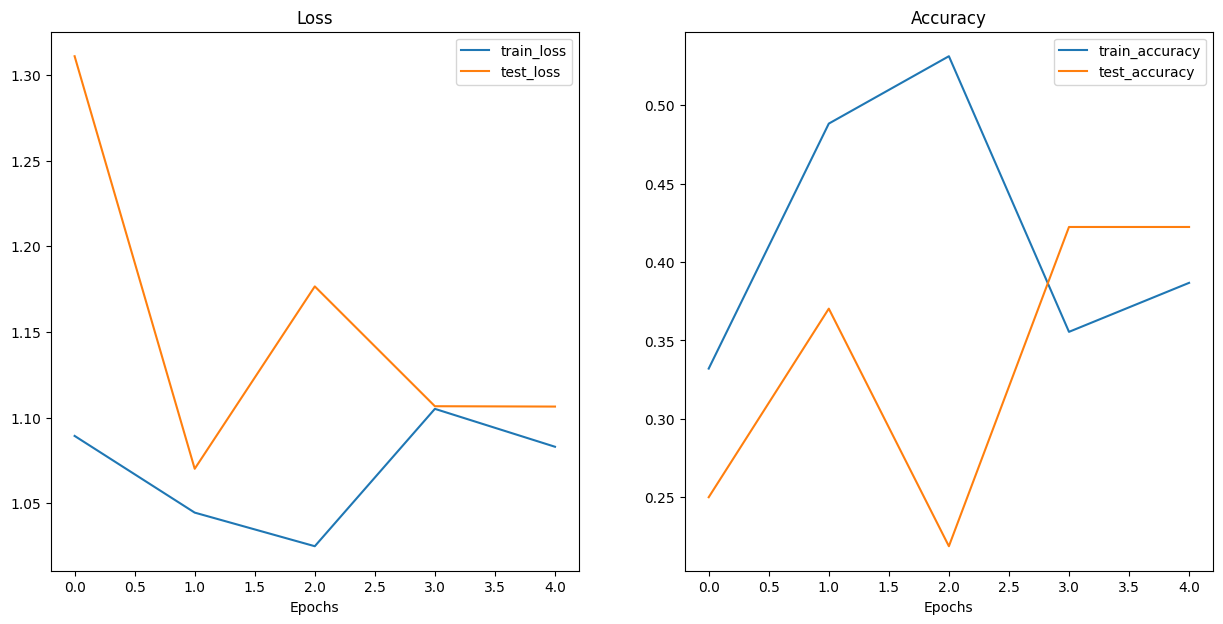

In [57]:
from helper_functions import plot_loss_curves
plot_loss_curves(results_vit_model)

# *HERE WE ARE GOING TO GET THE PERTRAINED MODEL BECAUSEE OUR MODEL IS GOOD BUT IT LACKS SOME ADVANCED TECHNIQES AND DATA BECAUSE WE HAVE USED VERY LOW AMOUNT OF DATA*

In [79]:
pre_trained_vit_weights = torchvision.models.ViT_B_16_Weights.DEFAULT
pre_trained_vit = torchvision.models.vit_b_16(weights=pre_trained_vit_weights).to(device)

In [80]:
summary(pre_trained_vit,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 224, 224]     [1, 1000]            768                  True
├─Conv2d (conv_proj)                                         [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Encoder (encoder)                                          [1, 197, 768]        [1, 197, 768]        151,296              True
│    └─Dropout (dropout)                                     [1, 197, 768]        [1, 197, 768]        --                   --
│    └─Sequential (layers)                                   [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 197, 768]        [1, 197, 768]        7,087,872            True
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 197, 768]        [1, 197, 768

In [81]:
#stop all parameters
for param in pre_trained_vit.parameters():
    param.requires_grad = False
#make the new head layer and that is the part that have our learnable parameter
pre_trained_vit.heads = nn.Linear(in_features=768, out_features=len(classes)).to(device)

In [82]:
summary(pre_trained_vit,
        input_size=(1,3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 224, 224]     [1, 3]               768                  Partial
├─Conv2d (conv_proj)                                         [1, 3, 224, 224]     [1, 768, 14, 14]     (590,592)            False
├─Encoder (encoder)                                          [1, 197, 768]        [1, 197, 768]        151,296              False
│    └─Dropout (dropout)                                     [1, 197, 768]        [1, 197, 768]        --                   --
│    └─Sequential (layers)                                   [1, 197, 768]        [1, 197, 768]        --                   False
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 197, 768]        [1, 197, 768]        (7,087,872)          False
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 197, 768]        [1, 1

## *GETTING THE MODEL TRANSFORM AND OTHER THINGS....... AND TRAIN*

In [83]:
pre_trained_vit_transform = pre_trained_vit_weights.transforms()
pre_trained_vit_transform

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [84]:
pre_trained_vit_train_dataloader , pre_trained_vit_test_dataloader , classes = data_setter_loader.data_setter_loader(train_dir, test_dir, pre_trained_vit_transform, 32, 1)

In [85]:
#make optimizer
optimizer = torch.optim.Adam(pre_trained_vit.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

In [86]:
pre_trained_vit_results = trainer.training_fn(pre_trained_vit,
                                              pre_trained_vit_train_dataloader,
                                              pre_trained_vit_test_dataloader,
                                              loss_fn,
                                              optimizer,
                                              10,
                                              device)

 10%|█         | 1/10 [00:11<01:41, 11.24s/it]

Epoch: 0 | Train loss: 0.8709 | Train acc: 57.8125 | Test loss: 0.5046 | Test acc: 87.7841


 20%|██        | 2/10 [00:22<01:28, 11.00s/it]

Epoch: 1 | Train loss: 0.3935 | Train acc: 95.3125 | Test loss: 0.2941 | Test acc: 92.8030


 30%|███       | 3/10 [00:32<01:16, 10.90s/it]

Epoch: 2 | Train loss: 0.2465 | Train acc: 95.7031 | Test loss: 0.2305 | Test acc: 92.8030


... (10 outputs left out)

 90%|█████████ | 9/10 [01:38<00:10, 10.89s/it]

Epoch: 8 | Train loss: 0.0974 | Train acc: 97.2656 | Test loss: 0.2043 | Test acc: 92.8030


100%|██████████| 10/10 [01:50<00:00, 11.03s/it]

Epoch: 9 | Train loss: 0.0878 | Train acc: 97.2656 | Test loss: 0.2035 | Test acc: 92.8030


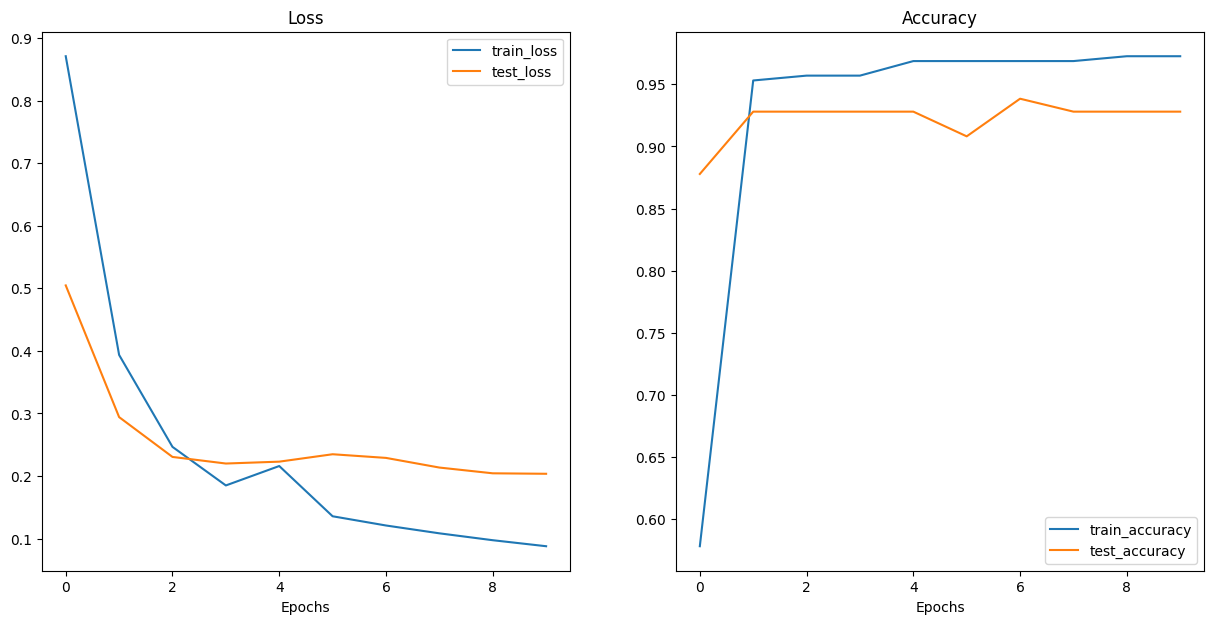

In [87]:
plot_loss_curves(pre_trained_vit_results)

## *SAVE THIS BEST PERFORMING MODEL*

In [91]:

from finished_stuff.going_modular import model_saver, random_image_model_test

model_saver.model_saver(pre_trained_vit, "../../models", "pre_trained_vit_model_copy_research_section.pth")

saving model to models\pre_trained_vit_modelcopy_research_section.pth


In [93]:
#see the size of the model
pretrained_vit_model_size = Path("../../models/pre_trained_vit_model_copy_research_section.pth").stat().st_size // (1024 * 1024)
print(f"Pretrained ViT feature extractor model size: {pretrained_vit_model_size} MB")

Pretrained ViT feature extractor model size: 327 MB


### *MAKING CUSTOM IMAGE PREDICTION*

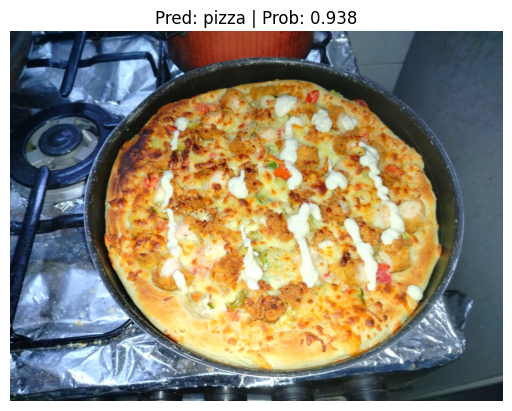

In [104]:

random_image_model_test.random_image_model_test(pre_trained_vit, "../data/my_pizza.jpg", classes, 224)